# Prior and posterior Gaussian processes for different kernels: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/gaussian_process/plot_gpr_prior_posterior.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/gaussian_process/plot_gpr_prior_posterior.html)).

**Scenario:** ten points of `sin((x - 2.5)^2)` on `[0, 5]` (`RandomState(4)`). For five kernels
(`1.0 * RBF`, `1.0 * RationalQuadratic`, `1.0 * ExpSineSquared`, `ConstantKernel * DotProduct ** 2` with
`normalize_y=True`, `1.0 * Matern(nu=1.5)`), a `GaussianProcessRegressor(kernel, random_state=0)` draws prior
mean/std and five `sample_y` functions on 100 grid points, is fitted (L-BFGS-B on the log-marginal likelihood), then
draws posterior mean/std/samples and reports the learned kernel and `log_marginal_likelihood(kernel_.theta)`.

**Adaptations:**
- Kernels are built with Moxie's typed constructors (`Bounds(lo, hi)` for sklearn's `(lo, hi)` tuples); `predict`
  with `return_std=True` returns a `PredictionResult` (`.mean`, `.std`), a documented family adaptation.
- Besides the end-to-end fit, Moxie also evaluates the posterior with `optimizer=None` at sklearn's learned
  `kernel_.theta` (`clone_with_theta`). That isolates the posterior algebra from the optimizer's stopping point.
- The example draws ten 2x1 figures. Here one figure per side (5 kernels x prior/posterior) at dpi 60 shows
  the same content.

**Determinism:** deterministic. Seeded data, `random_state=0` everywhere, and no restarts. L-BFGS-B iterates agree
only to optimizer resolution because the floating-point summation order differs, so optimized quantities get
optimizer-level tolerances. `sample_y` draws use the same standard-normal stream, mapped through an SVD square root whose
singular-vector signs are unspecified (documented in `docs/gaussian_process/regression/api.md`). Draws are compared
through their whitened norm, which is invariant to those signs.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("gaussian_process/plot_gpr_prior_posterior")

## 1. scikit-learn (Python reference)

Radial Basis Function kernel
Kernel parameters before fit:
1**2 * RBF(length_scale=1))
Kernel parameters after fit: 
0.594**2 * RBF(length_scale=0.279) 
Log-likelihood: -0.067

Rational Quadratic kernel
Kernel parameters before fit:
1**2 * RationalQuadratic(alpha=0.1, length_scale=1))
Kernel parameters after fit: 
0.594**2 * RationalQuadratic(alpha=5.39e+06, length_scale=0.279) 
Log-likelihood: -0.067

Exp-Sine-Squared kernel
Kernel parameters before fit:
1**2 * ExpSineSquared(length_scale=1, periodicity=3))
Kernel parameters after fit: 
0.799**2 * ExpSineSquared(length_scale=0.791, periodicity=2.87) 
Log-likelihood: 3.394

Dot-product kernel
Kernel parameters before fit:
0.316**2 * DotProduct(sigma_0=1) ** 2)
Kernel parameters after fit: 
3.16**2 * DotProduct(sigma_0=2.82) ** 2 
Log-likelihood: -18024693631.234

Matérn kernel
Kernel parameters before fit:
1**2 * Matern(length_scale=1, nu=1.5))
Kernel parameters after fit: 
0.609**2 * Matern(length_scale=0.484, nu=1.5) 
Log-likelihood:

/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:530: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  y_samples = rng.multivariate_normal(y_mean, y_cov, n_samples).T
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 5 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 10.0. Increasing the bound and calling f

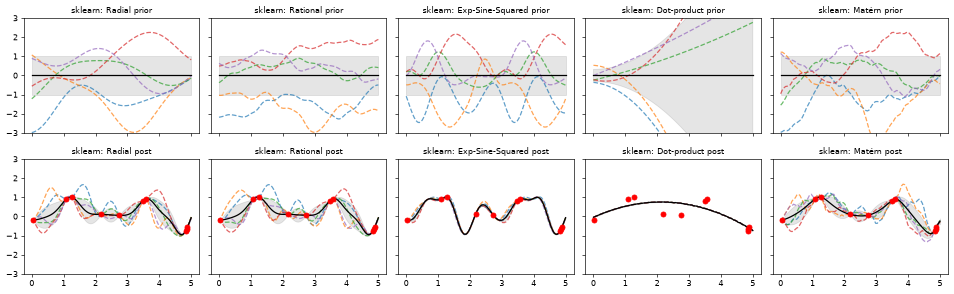

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (RBF, ConstantKernel, DotProduct, ExpSineSquared, Matern,
                                              RationalQuadratic)

x = np.linspace(0, 5, 100)
X = x.reshape(-1, 1)
rng = np.random.RandomState(4)
X_train = rng.uniform(0, 5, 10).reshape(-1, 1)
y_train = np.sin((X_train[:, 0] - 2.5) ** 2)
n_samples = 5

kernels = [
    ("Radial Basis Function kernel", 1.0 * RBF(length_scale=1.0, length_scale_bounds=(1e-1, 10.0)), {}),
    ("Rational Quadratic kernel", 1.0 * RationalQuadratic(length_scale=1.0, alpha=0.1, alpha_bounds=(1e-5, 1e15)), {}),
    ("Exp-Sine-Squared kernel", 1.0 * ExpSineSquared(length_scale=1.0, periodicity=3.0,
                                                      length_scale_bounds=(0.1, 10.0), periodicity_bounds=(1.0, 10.0)), {}),
    ("Dot-product kernel", ConstantKernel(0.1, (0.01, 10.0)) * (DotProduct(sigma_0=1.0, sigma_0_bounds=(0.1, 10.0)) ** 2),
     {"normalize_y": True}),
    ("Matérn kernel", 1.0 * Matern(length_scale=1.0, length_scale_bounds=(1e-1, 10.0), nu=1.5), {}),
]

sk = []
for title, kernel, extra in kernels:
    gpr = GaussianProcessRegressor(kernel=kernel, random_state=0, **extra)
    out = {"title": title}
    out["prior_mean"], out["prior_std"] = gpr.predict(X, return_std=True)
    out["prior_cov"] = gpr.predict(X, return_cov=True)[1]
    out["prior_samples"] = gpr.sample_y(X, n_samples)
    gpr.fit(X_train, y_train)
    out["post_mean"], out["post_std"] = gpr.predict(X, return_std=True)
    out["post_cov"] = gpr.predict(X, return_cov=True)[1]
    out["post_samples"] = gpr.sample_y(X, n_samples)
    out["theta"] = gpr.kernel_.theta
    out["lml"] = gpr.log_marginal_likelihood(gpr.kernel_.theta)
    out["lml_value_"] = gpr.log_marginal_likelihood_value_
    out["grad"] = gpr.log_marginal_likelihood(gpr.kernel_.theta, eval_gradient=True)[1]
    out["gpr"] = gpr
    out["kernel_"] = repr(gpr.kernel_)
    out["alpha_"], out["L_"] = gpr.alpha_, gpr.L_
    sk.append(out)
    print(f"{title}\nKernel parameters before fit:\n{kernel})")
    print(f"Kernel parameters after fit: \n{gpr.kernel_} \nLog-likelihood: {out['lml']:.3f}\n")


def plot_all(results, label):
    fig, axs = plt.subplots(2, 5, sharex=True, sharey=True, figsize=(16, 5), dpi=60)
    for col, r in enumerate(results):
        for row, stage in enumerate(("prior", "post")):
            ax = axs[row, col]
            for s in r[f"{stage}_samples"].T:
                ax.plot(x, s, linestyle="--", alpha=0.7)
            m, sd = r[f"{stage}_mean"], r[f"{stage}_std"]
            ax.plot(x, m, color="black")
            ax.fill_between(x, m - sd, m + sd, alpha=0.1, color="black")
            if stage == "post":
                ax.scatter(X_train[:, 0], y_train, color="red", zorder=10)
            ax.set_ylim([-3, 3])
            ax.set_title(f"{label}: {r['title'].split()[0]} {stage}", fontsize=9)
    plt.tight_layout()
    plt.show()


plot_all(sk, "sklearn")
nb.share(X=X, X_train=X_train, y_train=y_train)
for i, r in enumerate(sk):
    nb.share(**{f"sk_theta_{i}": r["theta"]})

## 2. Moxie (native Mojo)

Learning, prediction and sampling run in Mojo; Python only supplies the data and sklearn's optimum.

In [3]:
%%mojo prior_posterior
from moxie.gaussian_process import GaussianProcessRegressor
from moxie.gaussian_process.kernels import (Bounds, ConstantKernel, DotProduct, ExpSineSquared, Kernel, Matern, RBF,
                                            RationalQuadratic)
from moxie_nb_io import load, save, save_floats, save_strings


def kernel_for(which: Int) raises -> Kernel:
    if which == 0:
        return 1.0 * RBF(1.0, Bounds(1e-1, 10.0))
    if which == 1:
        return 1.0 * RationalQuadratic(length_scale=1.0, alpha=0.1, alpha_bounds=Bounds(1e-5, 1e15))
    if which == 2:
        return 1.0 * ExpSineSquared(1.0, 3.0, Bounds(0.1, 10.0), Bounds(1.0, 10.0))
    if which == 3:
        return ConstantKernel(0.1, Bounds(0.01, 10.0)) * (DotProduct(1.0, Bounds(0.1, 10.0)) ** 2)
    return 1.0 * Matern(1.0, Bounds(1e-1, 10.0), nu=1.5)


def main() raises:
    var X = load("X")
    var X_train = load("X_train")
    var y_train = load("y_train")
    var reprs = List[String]()
    var lml = List[Float64]()
    var lml_value = List[Float64]()
    var fixed_lml = List[Float64]()
    for which in range(5):
        var tag = String(which)
        var gpr = GaussianProcessRegressor(kernel_for(which), normalize_y=which == 3, random_state=0)
        var prior = gpr.predict(X, return_std=True)
        save("prior_mean_" + tag, prior.mean)
        save("prior_std_" + tag, prior.std.value())
        save("prior_samples_" + tag, gpr.sample_y(X, 5))
        _ = gpr.fit(X_train, y_train)
        var post = gpr.predict(X, return_std=True)
        save("post_mean_" + tag, post.mean)
        save("post_std_" + tag, post.std.value())
        save("post_cov_" + tag, gpr.predict(X, return_std=False, return_cov=True).covariance.value())
        save("post_samples_" + tag, gpr.sample_y(X, 5))
        save("theta_" + tag, gpr.kernel_.theta())
        lml.append(gpr.log_marginal_likelihood(gpr.kernel_.theta()).value)
        lml_value.append(gpr.log_marginal_likelihood_value_)
        reprs.append(String(gpr.kernel_))
        print(String(t"which {which}: kernel_ = {gpr.kernel_}  log-likelihood {lml[which]}"))

        # Posterior algebra at sklearn's optimum, without the optimizer.
        var at_sklearn = kernel_for(which).clone_with_theta(load("sk_theta_" + tag))
        var fixed = GaussianProcessRegressor(at_sklearn, optimizer=None, normalize_y=which == 3, random_state=0)
        _ = fixed.fit(X_train, y_train)
        var fixed_post = fixed.predict(X, return_std=True)
        save("fixed_mean_" + tag, fixed_post.mean)
        save("fixed_std_" + tag, fixed_post.std.value())
        save("fixed_alpha_" + tag, fixed.alpha_)
        save("fixed_L_" + tag, fixed.L_)
        fixed_lml.append(fixed.log_marginal_likelihood_value_)
        var at_theta = fixed.log_marginal_likelihood(load("sk_theta_" + tag), eval_gradient=True)
        save("grad_at_sk_" + tag, at_theta.gradient.value())
    save_strings("kernel_repr", reprs)
    save_floats("lml", lml)
    save_floats("lml_value", lml_value)
    save_floats("fixed_lml", fixed_lml)

which 0: kernel_ = 0.594**2 * RBF(length_scale=0.279)  log-likelihood -0.06737756217156488
which 1: kernel_ = 0.593**2 * RationalQuadratic(alpha=1.4e+11, length_scale=0.278)  log-likelihood -0.027346665871911924
which 2: kernel_ = 0.799**2 * ExpSineSquared(length_scale=0.791, periodicity=2.87)  log-likelihood 3.393829846455402
which 3: kernel_ = 0.77**2 * DotProduct(sigma_0=0.416) ** 2.0  log-likelihood -18106752302.54804
which 4: kernel_ = 0.609**2 * Matern(length_scale=0.484, nu=1.5)  log-likelihood -1.1853244856659693


## 3. Side by side and parity

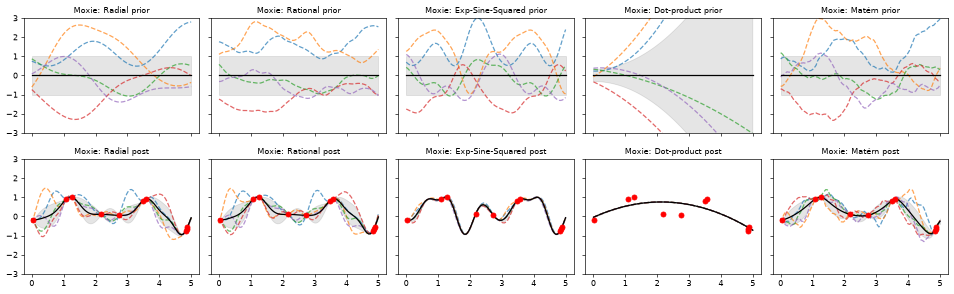

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
Radial: prior mean,PASS,"(100,)","(100,)",,,exact,0 mismatches,
Radial: prior std,PASS,"(100,)","(100,)",0,0,"rtol=1e-12, atol=1e-14",,kernel diag at fixed hyperparameters; libm exp/sqrt only
Radial: prior sample_y whitened |z|^2,PASS,"(5,)","(5,)",2.6e-09,2.65e-10,"rtol=1e-06, atol=0",,"same N(0, I) stream; SVD singular-vector signs differ, so only the whitened norm over well-resolved components (eig > 1e-8 max) is invariant; components near the cutoff carry ~sqrt(eps) noise"
Radial: kernel_.theta,PASS,"(2,)","(2,)",8.83e-13,8.47e-13,"rtol=1e-06, atol=1e-06",,"same SciPy-faithful L-BFGS-B from the same start; kernel/LML sums differ only in floating-point order, and the observed iterates agree to <= 2e-7 relative (ExpSineSquared, the flattest well-posed surface)"
Radial: log_marginal_likelihood(kernel_.theta),PASS,(),(),1.33e-12,1.97e-11,"rtol=1e-09, atol=0",,"LML is stationary at the optimum, so the theta offset enters only to second order"
Radial: log_marginal_likelihood_value_,PASS,(),(),1.33e-12,1.97e-11,"rtol=1e-09, atol=0",,as above
Radial: posterior mean,PASS,"(100,)","(100,)",1.37e-12,1.67e-11,"rtol=1e-06, atol=1e-07",,"same SciPy-faithful L-BFGS-B from the same start; kernel/LML sums differ only in floating-point order, and the observed iterates agree to <= 2e-7 relative (ExpSineSquared, the flattest well-posed surface)"
Radial: posterior std,PASS,"(100,)","(100,)",1.02e-12,1.01e-08,"rtol=1e-06, atol=1e-07",,"same SciPy-faithful L-BFGS-B from the same start; kernel/LML sums differ only in floating-point order, and the observed iterates agree to <= 2e-7 relative (ExpSineSquared, the flattest well-posed surface); std near training points is ~1e-5, so relative error is amplified"
Radial: posterior sample_y whitened |z|^2,PASS,"(5,)","(5,)",1.2e-08,2.94e-10,"rtol=1e-06, atol=0",,"same N(0, I) stream; SVD singular-vector signs differ, so only the whitened norm over well-resolved components (eig > 1e-8 max) is invariant; components near the cutoff carry ~sqrt(eps) noise"
Radial: kernel_ repr,PASS,"(1,)","(1,)",,,exact,0 mismatches,


In [4]:
mx = nb.results["prior_posterior"]
plot_all([{"title": r["title"], **{f"{s}_{q}": mx[f"{s}_{q}_{i}"] for s in ("prior", "post")
           for q in ("mean", "std", "samples")}} for i, r in enumerate(sk)], "Moxie")
moxie_nb.side_by_side(sklearn=np.array([r["kernel_"] for r in sk]), moxie=mx["kernel_repr"])


def whitened(samples, mean, cov, rcond=1e-8):
    """|z|^2 over the covariance components above rcond * largest eigenvalue (sign-invariant)."""
    w, v = np.linalg.eigh(cov)
    keep = w > rcond * w.max()
    proj = v[:, keep].T @ (samples - mean[:, None])
    return np.sum(proj ** 2 / w[keep][:, None], axis=0)


OPT = ("same SciPy-faithful L-BFGS-B from the same start; kernel/LML sums differ only in floating-point order, "
       "and the observed iterates agree to <= 2e-7 relative (ExpSineSquared, the flattest well-posed surface)")
WHITE = ("same N(0, I) stream; SVD singular-vector signs differ, so only the whitened norm over well-resolved "
         "components (eig > 1e-8 max) is invariant; components near the cutoff carry ~sqrt(eps) noise")
WELL_POSED = (0, 2, 4)  # RBF, ExpSineSquared, Matern
for i, r in enumerate(sk):
    name = r["title"].split()[0]
    nb.compare(f"{name}: prior mean", r["prior_mean"], mx[f"prior_mean_{i}"], exact=True)
    nb.compare(f"{name}: prior std", r["prior_std"], mx[f"prior_std_{i}"], rtol=1e-12, atol=1e-14,
               reason="kernel diag at fixed hyperparameters; libm exp/sqrt only")
    nb.compare(f"{name}: prior sample_y whitened |z|^2", whitened(r["prior_samples"], r["prior_mean"], r["prior_cov"]),
               whitened(mx[f"prior_samples_{i}"], r["prior_mean"], r["prior_cov"]), rtol=1e-6, reason=WHITE)
    if i in WELL_POSED:
        nb.compare(f"{name}: kernel_.theta", r["theta"], mx[f"theta_{i}"], rtol=1e-6, atol=1e-6, reason=OPT)
        nb.compare(f"{name}: log_marginal_likelihood(kernel_.theta)", r["lml"], mx["lml"][i], rtol=1e-9,
                   reason="LML is stationary at the optimum, so the theta offset enters only to second order")
        nb.compare(f"{name}: log_marginal_likelihood_value_", r["lml_value_"], mx["lml_value"][i], rtol=1e-9,
                   reason="as above")
        nb.compare(f"{name}: posterior mean", r["post_mean"], mx[f"post_mean_{i}"], rtol=1e-6, atol=1e-7, reason=OPT)
        nb.compare(f"{name}: posterior std", r["post_std"], mx[f"post_std_{i}"], rtol=1e-6, atol=1e-7,
                   reason=OPT + "; std near training points is ~1e-5, so relative error is amplified")
        nb.compare(f"{name}: posterior sample_y whitened |z|^2",
                   whitened(r["post_samples"], r["post_mean"], r["post_cov"]),
                   whitened(mx[f"post_samples_{i}"], mx[f"post_mean_{i}"], mx[f"post_cov_{i}"]), rtol=1e-6,
                   reason=WHITE)
        nb.compare(f"{name}: kernel_ repr", np.array([r["kernel_"]]), mx["kernel_repr"][i:i + 1], exact=True)
    if i != 3:
        nb.compare(f"{name}: at sklearn theta, posterior mean", r["post_mean"], mx[f"fixed_mean_{i}"], rtol=1e-8,
                   atol=1e-9, reason="identical hyperparameters; Cholesky/triangular-solve summation order on a "
                                     "10x10 system (K + 1e-10 I, condition number up to ~1e8)")
        nb.compare(f"{name}: at sklearn theta, posterior std", r["post_std"], mx[f"fixed_std_{i}"], rtol=1e-6,
                   atol=1e-9, reason="std = sqrt(k(x,x) - |v|^2) cancels near training points, amplifying "
                                     "1e-16-level variance differences relative to std ~1e-5")
        nb.compare(f"{name}: at sklearn theta, alpha_", r["alpha_"], mx[f"fixed_alpha_{i}"], rtol=1e-8, atol=1e-6,
                   reason="alpha_ = K^-1 y on an ill-conditioned K (cond ~1e8): error ~cond * eps * |alpha_|")
        nb.compare(f"{name}: at sklearn theta, L_", r["L_"], mx[f"fixed_L_{i}"], rtol=1e-9, atol=1e-12,
                   reason="Cholesky factor of the same matrix; summation order only")
        nb.compare(f"{name}: at sklearn theta, LML", r["lml"], mx["fixed_lml"][i], rtol=1e-9,
                   reason="same hyperparameters; log-det and quadratic-form summation order")

# RationalQuadratic: alpha_bounds reach 1e15 and the optimum alpha is ~5e6, where RQ ~ RBF and
# d/dlog(alpha) is cancellation noise: -alpha*log(b) + d^2/(2 l^2 b) with b = 1 + O(1e-8).
rq = sk[1]
pinned = rq["gpr"]
moxie_theta = mx["theta_1"]
nb.compare("Rational: LML and its length-scale/constant gradient at sklearn theta",
           np.r_[rq["lml"], rq["grad"][[0, 2]]], np.r_[mx["fixed_lml"][1], mx["grad_at_sk_1"][[0, 2]]],
           rtol=1e-6, atol=1e-8, reason="well-conditioned directions agree; same formula and operation order")
moxie_nb.side_by_side(sklearn_grad_at_sklearn_theta=rq["grad"], moxie_grad_at_sklearn_theta=mx["grad_at_sk_1"])
nb.compare("Rational: Moxie optimum is at least as good under sklearn's own LML",
           [pinned.log_marginal_likelihood(moxie_theta) >= rq["lml"] - 1e-9], [True], exact=True)
nb.note("Rational: optimized theta / posterior after fit", "ADAPTED",
        f"not compared numerically: sklearn stops at log(alpha)={rq['theta'][1]:.2f}, Moxie at {moxie_theta[1]:.2f}. "
        "Above alpha ~1e6 the d LML / d log(alpha) component is cancellation noise in both implementations "
        "(sklearn's own value at its optimum is shown above), so the L-BFGS-B paths split on rounding. "
        "sklearn's LML at Moxie's endpoint is higher than at its own, and both posteriors match at a common theta.")

# DotProduct ** 2 with normalize_y: rank-3 kernel + 1e-10 jitter, cond(K) ~4e14; sklearn's L-BFGS-B ends ABNORMAL.
dp = sk[3]
g = dp["gpr"]
L = np.longdouble
c, s0 = np.exp(L(dp["theta"][0])), np.exp(L(dp["theta"][1]))
xt, xs = X_train[:, 0].astype(L), X[:, 0].astype(L)
K = c * (s0 ** 2 + np.outer(xt, xt)) ** 2 + L(1e-10) * np.eye(10, dtype=L)
Ks = c * (s0 ** 2 + np.outer(xs, xt)) ** 2
yl = y_train.astype(L); m_, sd_ = yl.mean(), np.sqrt(((yl - yl.mean()) ** 2).mean())
Lc = np.zeros((10, 10), dtype=L)
for j in range(10):
    Lc[j, j] = np.sqrt(K[j, j] - np.sum(Lc[j, :j] ** 2))
    for k in range(j + 1, 10):
        Lc[k, j] = (K[k, j] - np.sum(Lc[k, :j] * Lc[j, :j])) / Lc[j, j]
z = np.zeros(10, dtype=L)
for k in range(10):
    z[k] = ((yl[k] - m_) / sd_ - np.dot(Lc[k, :k], z[:k])) / Lc[k, k]
a = np.zeros(10, dtype=L)
for k in reversed(range(10)):
    a[k] = (z[k] - np.dot(Lc[k + 1:, k], a[k + 1:])) / Lc[k, k]
ref_alpha, ref_mean = a.astype(float), ((Ks @ a) * sd_ + m_).astype(float)
err = lambda v, ref: float(np.max(np.abs(v - ref) / np.maximum(np.abs(ref), 1e-300)))
sk_err, mx_err = err(dp["alpha_"], ref_alpha), err(mx["fixed_alpha_3"], ref_alpha)
sk_merr = float(np.max(np.abs(dp["post_mean"] - ref_mean))); mx_merr = float(np.max(np.abs(mx["fixed_mean_3"] - ref_mean)))
moxie_nb.side_by_side(cond_K=[np.linalg.cond(K.astype(float))], alpha_rel_err_sklearn=[sk_err], alpha_rel_err_moxie=[mx_err],
                      mean_abs_err_sklearn=[sk_merr], mean_abs_err_moxie=[mx_merr])
nb.compare("Dot-product: at sklearn theta, alpha_ error vs long-double reference no worse than sklearn's",
           [mx_err <= sk_err], [True], exact=True)
nb.compare("Dot-product: at sklearn theta, posterior-mean error vs long-double reference no worse than sklearn's",
           [mx_merr <= sk_merr], [True], exact=True)
nb.compare("Dot-product: at sklearn theta, L_", dp["L_"], mx["fixed_L_3"], rtol=1e-6, atol=1e-6,
           reason="leading entries of the same factor; trailing pivots are ~sqrt(1e-10) and carry cond*eps error")
nb.compare("Dot-product: at sklearn theta, LML", dp["lml"], mx["fixed_lml"][3], rtol=1e-2,
           reason="LML ~ -|P_perp y|^2 / 2e-10 is computed through a cond ~4e14 solve: ~1e-2 relative is the "
                  "float64 accuracy of either implementation")
nb.compare("Dot-product: at sklearn theta, posterior std", dp["post_std"], mx["fixed_std_3"], rtol=1e-6, atol=1e-6,
           reason="variance = k - |v|^2 after a cond ~4e14 triangular solve; absolute error ~sqrt(cond*eps)*1e-6")
nb.note("Dot-product: optimized theta / posterior after fit", "ADAPTED",
        "not compared numerically: sklearn's own L-BFGS-B run ends ABNORMAL after 5 iterations on an LML whose "
        "float64 value carries ~1e-2 relative noise (cond ~4e14), so neither endpoint is reproducible across "
        "BLAS/LAPACK builds. At a common theta Moxie is at least as accurate as sklearn (above).")
nb.note("Dot-product: kernel_ repr", "ADAPTED",
        "Exponentiation.exponent is a Float64, so Moxie prints '** 2.0' where sklearn prints the Python int "
        "exponent as '** 2' (documented in docs/gaussian_process/kernels/api.md)")
nb.note("sample_y on indefinite posteriors", "PASS",
        "the RationalQuadratic posterior has eigenvalues down to -1.8e-8; NumPy warns and draws, and Moxie now does "
        "the same (check_valid='warn'); it raised before this verification")
nb.report()
nb.assert_parity()